# Advanced Data Mining for Data-Driven Insights and Predictive Modeling

## Deliverable 3: Classification, Clustering, and Pattern Mining

### Student Name: Navya Katta

### Step 1: Import Libraries and Load Dataset

#### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from mlxtend.frequent_patterns import apriori, association_rules

sns.set_theme(style="whitegrid")

#### Load Dataset

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


### Step 2: Classification Data Preparation

#### Prepare Features and Target

In [3]:
# Create a working copy
df_model = df.copy()

# Create previous-contact indicator
df_model["previously_contacted"] = (df_model["pdays"] != -1).astype(int)

# Replace special value after preserving its meaning
df_model["pdays"] = df_model["pdays"].replace(-1, 0)

# Prepare predictors and target
X = df_model.drop(columns=["y", "duration"])
y = df_model["y"].map({"no": 0, "yes": 1})

# Identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()

categorical_cols = X.select_dtypes(include=["object", "str"]).columns.tolist()

# Preprocessing pipeline
preprocessor = ColumnTransformer([("num", StandardScaler(), numeric_cols),("cat", OneHotEncoder(handle_unknown="ignore"),categorical_cols)])

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42,stratify=y)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 36168
Testing Records: 9043


#### Interpretation

The dataset was prepared for classification by converting the subscription outcome into binary values. Numerical attributes were standardized, and categorical features were encoded. An 80:20 stratified train-test split was applied to preserve the original class distribution. Call duration was excluded to prevent post-contact information leakage.

### Step 3: Build Two Classification Models

#### Decision Tree Classifier

In [4]:
# Decision Tree pipeline
dt_model = Pipeline([("preprocessing", preprocessor),("classifier", DecisionTreeClassifier(max_depth=5,random_state=42))])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


#### K-Nearest Neighbors

In [5]:
# KNN pipeline
knn_model = Pipeline([("preprocessing", preprocessor),("classifier", KNeighborsClassifier(n_neighbors=5))])

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

print("KNN trained successfully.")

KNN trained successfully.


### Step 4: Hyperparameter Tuning

#### GridSearchCV

In [6]:
# Parameters to tune
param_grid = {"classifier__max_depth": [3, 5, 7, 10],"classifier__min_samples_split": [2, 10, 20],"classifier__min_samples_leaf": [1, 5, 10]}

# Grid search with 3-fold cross-validation
grid_search = GridSearchCV(dt_model,param_grid,cv=3,scoring="f1",n_jobs=-1)

grid_search.fit(X_train, y_train)

best_dt_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10}
Best CV F1 Score: 0.30573434420079415


#### Interpretation

GridSearchCV was applied to optimize the Decision Tree classifier using three-fold cross-validation. The best parameters were a maximum depth of 10, minimum samples split of 10, and minimum samples leaf of 1. The optimized model achieved a cross-validation F1-score of 0.3057. This relatively low score indicates difficulty identifying customers who subscribed to term deposits, potentially due to class imbalance. Further improvements could include class weighting, alternative hyperparameters, or additional feature engineering.

### Step 5: Classification Model Evaluation

#### Compare Classification Models

In [7]:
models = {"Decision Tree": dt_model,"KNN": knn_model,"Tuned Decision Tree": best_dt_model}

classification_results = []

for name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    classification_results.append({"Model": name,"Accuracy": accuracy_score(y_test, predictions),"F1 Score": f1_score(y_test, predictions),
        "ROC AUC": roc_auc_score(y_test, probabilities)})

results_df = pd.DataFrame(classification_results)

display(results_df.round(4))

,Model,Accuracy,F1 Score,ROC AUC
0,Decision Tree,0.8927,0.2445,0.7055
1,KNN,0.8878,0.2985,0.7032
2,Tuned Decision Tree,0.8911,0.3212,0.7215


#### Interpretation

The Tuned Decision Tree achieved the best overall classification performance, with an F1-score of 0.3212 and ROC AUC of 0.7215. Although the original Decision Tree achieved slightly higher accuracy (89.27%), its lower F1-score indicates weaker performance in identifying subscribers. Hyperparameter tuning improved the model's ability to balance precision and recall, making the Tuned Decision Tree the preferred model.

#### Confusion Matrix

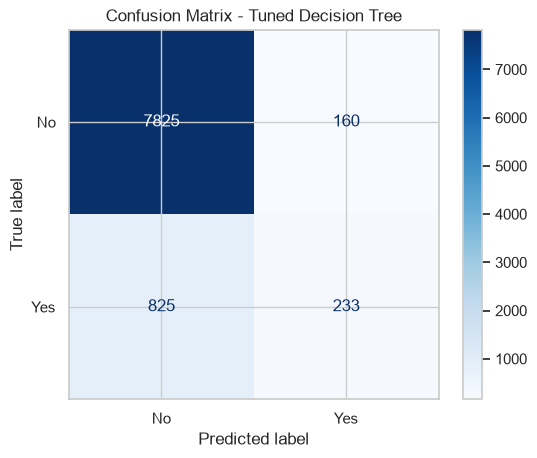

              precision    recall  f1-score   support

          No       0.90      0.98      0.94      7985
         Yes       0.59      0.22      0.32      1058

    accuracy                           0.89      9043
   macro avg       0.75      0.60      0.63      9043
weighted avg       0.87      0.89      0.87      9043



In [8]:
# Confusion matrix for tuned Decision Tree
ConfusionMatrixDisplay.from_estimator(best_dt_model,X_test,y_test,display_labels=["No", "Yes"],cmap="Blues")

plt.title("Confusion Matrix - Tuned Decision Tree")
plt.show()

print(classification_report(y_test,best_dt_model.predict(X_test),target_names=["No", "Yes"],zero_division=0))

#### Interpretation

The confusion matrix results show that the Tuned Decision Tree achieved an overall accuracy of 89%. The model performed well in identifying non-subscribers, achieving 90% precision and 98% recall. However, its performance in identifying subscribers was weaker, with 59% precision, 22% recall, and an F1-score of 0.32. This indicates that the model missed many actual subscribers due to class imbalance. Techniques such as class weighting or threshold adjustment could improve minority-class detection.

#### ROC Curve

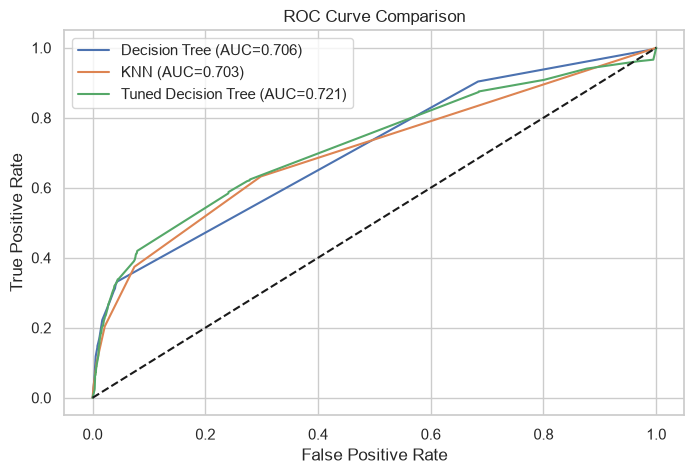

In [9]:
plt.figure(figsize=(8, 5))

for name, model in models.items():

    probabilities = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probabilities)

    auc = roc_auc_score(y_test, probabilities)

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

#### Interpretation

The ROC curve comparison shows that the Tuned Decision Tree achieved the highest AUC of 0.7215, followed by the original Decision Tree (0.7055) and KNN (0.7032). All three models performed better than random classification.

#### Classification Performance Comparison

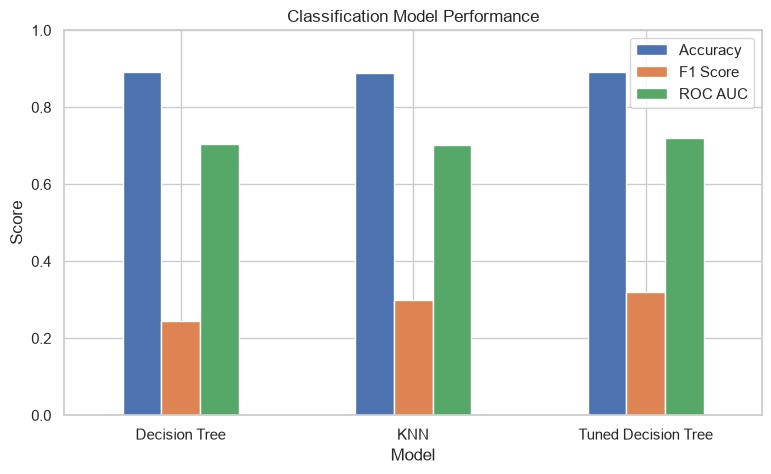

In [10]:
results_df.plot(x="Model",y=["Accuracy", "F1 Score", "ROC AUC"],kind="bar",figsize=(9, 5))

plt.title("Classification Model Performance")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend()
plt.show()

#### Interpretation

The performance comparison chart shows that all three models achieved approximately 89% accuracy. However, their F1-scores were considerably lower because of the imbalanced subscription classes. The Tuned Decision Tree achieved the highest F1-score (0.3212) and ROC AUC (0.7215), demonstrating the benefits of hyperparameter tuning. 

### Step 6: K-Means Clustering

#### Prepare Clustering Features

In [11]:
cluster_features = ["age", "balance", "campaign","previously_contacted"]

X_cluster = df_model[cluster_features].copy()

scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

print("Clustering Data Shape:", X_cluster_scaled.shape)

Clustering Data Shape: (45211, 4)


#### Interpretation

Four numerical features were selected and standardized for clustering. The resulting dataset contained 45,211 records and 4 features, ensuring consistent scaling for K-Means.

#### K-Means

In [12]:
kmeans = KMeans(n_clusters=3,random_state=42,n_init=10)

clusters = kmeans.fit_predict(X_cluster_scaled)

df_model["Cluster"] = clusters

print(df_model["Cluster"].value_counts())

Cluster
1    22426
2    14564
0     8221
Name: count, dtype: int64


#### Interpretation

K-Means divided customers into three clusters: Cluster 0 (8,221), Cluster 1 (22,426), and Cluster 2 (14,564). Cluster 1 contained the largest number of customers.

#### Visualize Clusters Using PCA

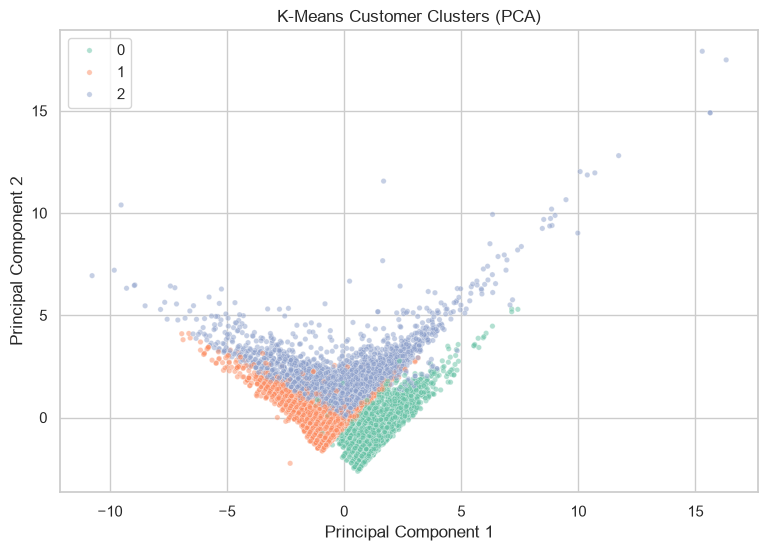

In [13]:
pca = PCA(n_components=2, random_state=42)

cluster_pca = pca.fit_transform(X_cluster_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(x=cluster_pca[:, 0],y=cluster_pca[:, 1],hue=clusters,palette="Set2",s=15,alpha=0.5,legend="full")

plt.title("K-Means Customer Clusters (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

#### Interpretation

The PCA visualization shows three partially separated customer clusters, with some overlapping observations. This suggests differences in customer characteristics while indicating that the groups are not completely distinct.

#### Interpret Cluster Groups

In [14]:
cluster_summary = df_model.groupby("Cluster")[cluster_features].mean().round(2)

cluster_summary["Customer Count"] = (df_model.groupby("Cluster").size())

display(cluster_summary)

,age,balance,campaign,previously_contacted,Customer Count
Cluster,,,,,
0,40.77,1513.10,2.05,1.0,8221
1,34.03,905.46,2.65,0.0,22426
2,51.66,1980.55,3.34,0.0,14564


#### Interpretation

Cluster 0 represents previously contacted customers, Cluster 1 consists of younger customers with lower average balances, and Cluster 2 includes older customers with higher balances and more campaign contacts. These segments could support targeted marketing strategies.

### Step 7: Association Rule Mining Using Apriori

#### Prepare Transaction Data

In [15]:
# Select categorical variables for association mining
association_cols = ["job", "marital", "education","housing", "loan", "y"]

# Convert attributes into category=value items
transactions = pd.get_dummies(df[association_cols].astype(str),prefix=association_cols,prefix_sep="=",dtype=bool)

print("Transaction Shape:", transactions.shape)
display(transactions.head())

Transaction Shape: (45211, 25)


,job=admin.,job=blue-collar,job=entrepreneur,job=housemaid,job=management,job=retired,job=self-employed,job=services,job=student,job=technician,...,education=primary,education=secondary,education=tertiary,education=unknown,housing=no,housing=yes,loan=no,loan=yes,y=no,y=yes
0,False,False,False,False,True,False,False,False,False,False,...,False,False,True,False,False,True,True,False,True,False
1,False,False,False,False,False,False,False,False,False,True,...,False,True,False,False,False,True,True,False,True,False
2,False,False,True,False,False,False,False,False,False,False,...,False,True,False,False,False,True,False,True,True,False
3,False,True,False,False,False,False,False,False,False,False,...,False,False,False,True,False,True,True,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,True,False,True,False,True,False


#### Interpretation

The selected categorical attributes were converted into 25 binary features across 45,211 records using one-hot encoding.

#### Apply Apriori

In [16]:
# Identify frequent itemsets
frequent_itemsets = apriori(transactions,min_support=0.02,use_colnames=True,max_len=3)

print("Frequent Itemsets:", len(frequent_itemsets))

display(frequent_itemsets.sort_values("support", ascending=False).head(10))

Frequent Itemsets: 360


,support,itemsets
22,0.883015,frozenset({y=no})
20,0.839774,frozenset({loan=no})
139,0.733494,"frozenset({y=no, loan=no})"
12,0.601933,frozenset({marital=married})
19,0.555838,frozenset({housing=yes})
101,0.540997,"frozenset({y=no, marital=married})"
15,0.513194,frozenset({education=secondary})
137,0.513039,"frozenset({y=no, housing=yes})"
99,0.498861,"frozenset({loan=no, marital=married})"
135,0.459247,"frozenset({loan=no, housing=yes})"


#### Interpretation

The Apriori algorithm identified 360 frequent itemsets using a minimum support threshold of 0.02. The most frequent patterns included non-subscription (y=no, 88.30%), no personal loan (83.98%), and married customers (60.19%).

#### Generate Association Rules

In [19]:
# Generate rules using confidence
rules = association_rules(frequent_itemsets,metric="confidence",min_threshold=0.5)

# Select meaningful rules
rules = rules[(rules["lift"] > 1) &(rules["confidence"] >= 0.5)].copy()

# Sort rules by lift
rules = rules.sort_values("lift", ascending=False)

display(rules[["antecedents","consequents","support","confidence","lift"]].head(10))

,antecedents,consequents,support,confidence,lift
145,"frozenset({education=primary, housing=yes})",frozenset({job=blue-collar}),0.058570,0.680021,3.159105
198,"frozenset({marital=single, job=management})",frozenset({education=tertiary}),0.057154,0.876824,2.980384
183,"frozenset({education=tertiary, marital=divorced})",frozenset({job=management}),0.020283,0.623385,2.979898
222,"frozenset({job=management, y=yes})",frozenset({education=tertiary}),0.025082,0.871637,2.962754
187,"frozenset({education=tertiary, marital=married})",frozenset({job=management}),0.095110,0.610969,2.920546
207,"frozenset({education=tertiary, housing=yes})",frozenset({job=management}),0.084139,0.596425,2.851023
206,"frozenset({job=management, housing=no})",frozenset({education=tertiary}),0.088408,0.836192,2.842275
220,frozenset({job=management}),"frozenset({y=no, education=tertiary})",0.147464,0.704906,2.819062
216,"frozenset({y=no, education=tertiary})",frozenset({job=management}),0.147464,0.589739,2.819062
213,frozenset({job=management}),"frozenset({education=tertiary, loan=no})",0.150118,0.717594,2.816977


#### Interpretation

Association rules were generated using a minimum confidence of 0.50 and lift greater than 1. The strongest displayed rule linked primary education and housing loans to blue-collar employment, with 68% confidence and a lift of 3.16, indicating a positive association.

#### Visualize Association Rules

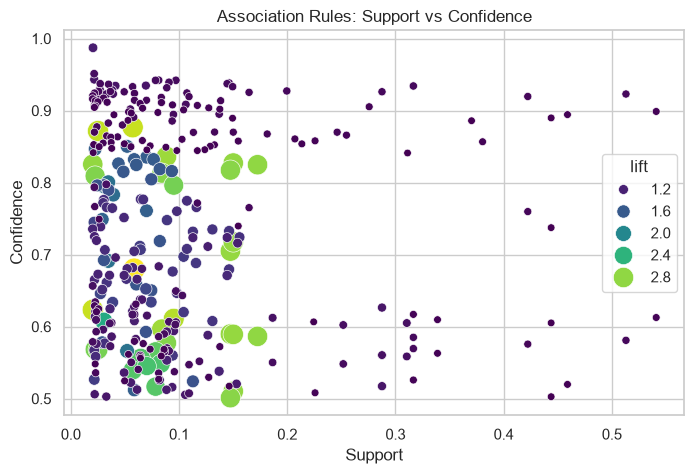

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=rules,x="support",y="confidence",size="lift",hue="lift",palette="viridis",sizes=(30, 250))

plt.title("Association Rules: Support vs Confidence")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.show()

#### Interpretation

The scatterplot illustrates relationships between support, confidence, and lift. Most rules have relatively low support but moderate-to-high confidence, while rules with higher lift indicate stronger associations between customer characteristics.

### Final Insights and Conclusion

Deliverable 3 successfully applied classification, clustering, and association rule mining techniques to the Bank Marketing Dataset. The **Tuned Decision Tree** achieved the best overall classification performance, with an accuracy of 89.11%, F1-score of 0.3212, and ROC AUC of 0.7215. However, its low subscriber recall of 22% highlighted challenges associated with class imbalance.

K-Means clustering identified three customer segments based on age, account balance, campaign contacts, and previous interactions. These groups revealed differences in customer characteristics that could support targeted marketing strategies.

Apriori association rule mining identified **360 frequent itemsets** and meaningful relationships among customer attributes. The strongest displayed rule achieved a lift of 3.16, indicating a positive association between primary education, housing loans, and blue-collar employment.

Overall, the findings demonstrate how data mining techniques can support customer segmentation, subscription prediction, and marketing decisions. Future improvements could include class balancing, additional feature engineering, and further model optimization to improve predictive performance.